# Example of the AiTLAS toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import UDD5Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 160


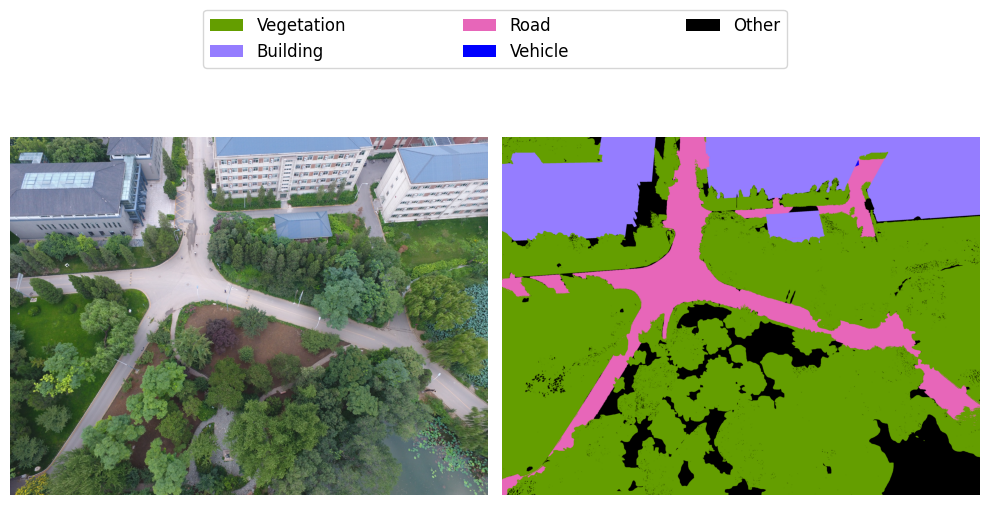

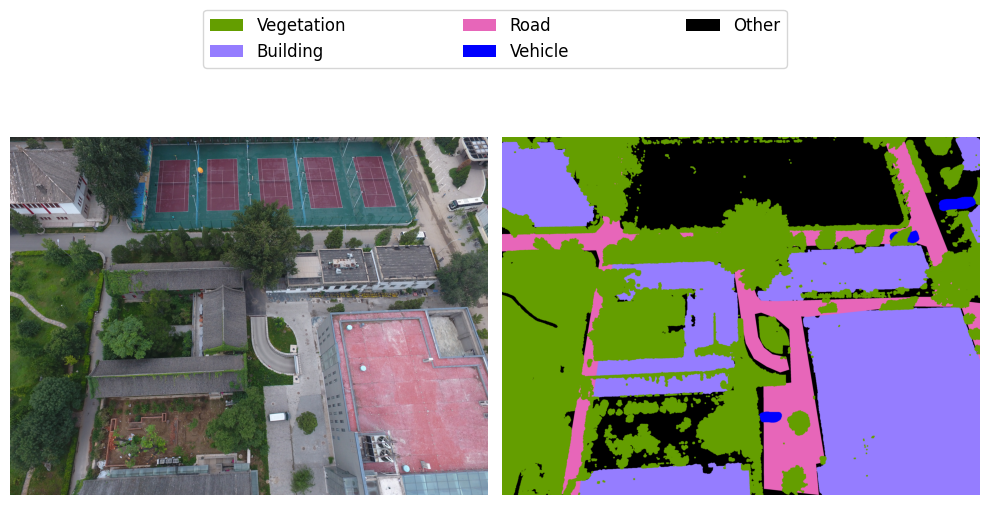

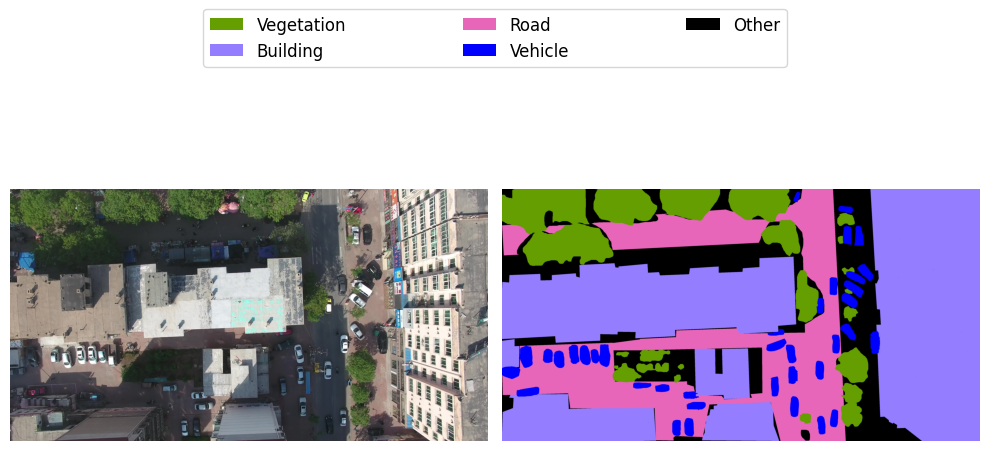

In [ ]:
dataset_config = {
    "data_dir": "./data/UDD5"
}
dataset = UDD5Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(15);
dataset.show_image(112);

In [15]:
dataset.data_distribution_table()

,Number of pixels
Vegetation,521085253.0
Building,684991192.0
Road,234514875.0
Vehicle,15029111.0
Other,304205489.0


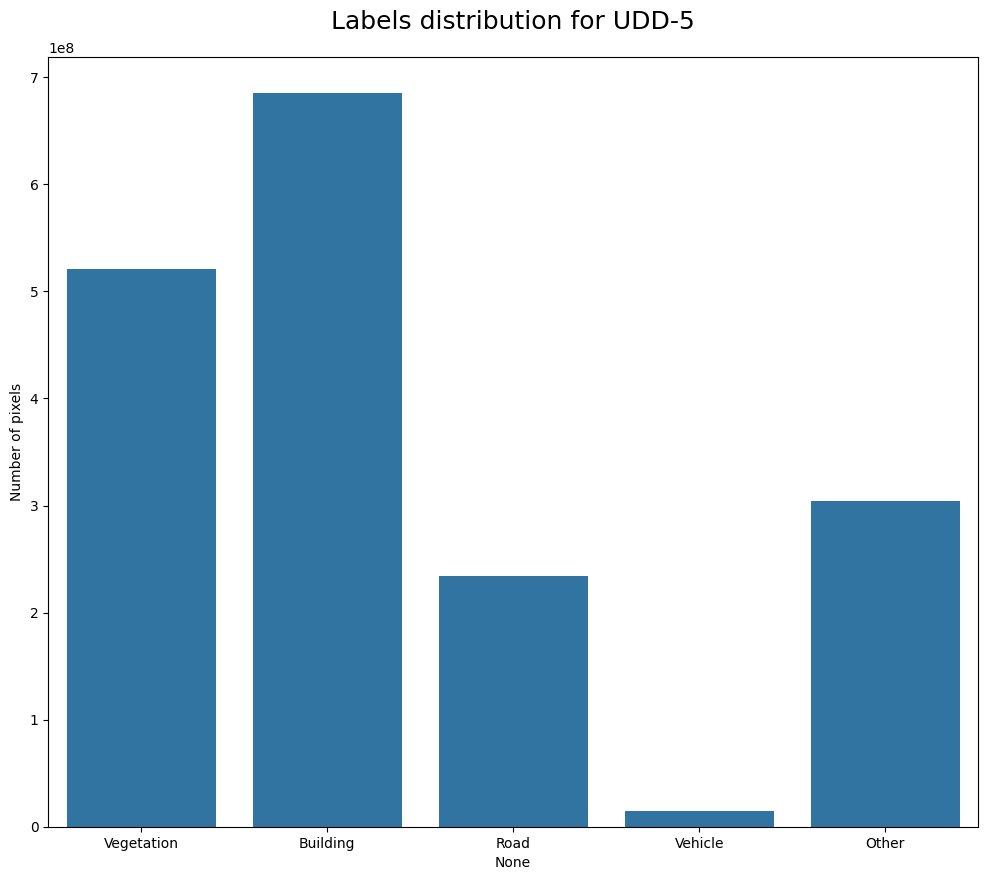

In [16]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/UDD5/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = UDD5Dataset(train_dataset_config)
len(train_dataset)

120

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/UDD5"
model_config = {
    "num_classes": 5, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [19]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-02-26 13:28:48,032 INFO Starting training.
training: 100%|██████████| 15/15 [00:21<00:00,  1.46s/it]
2025-02-26 13:29:09,959 INFO epoch: 1, time: 21, loss:  0.68076
testing on train set: 100%|██████████| 15/15 [00:21<00:00,  1.43s/it]
2025-02-26 13:29:32,860 INFO IOU:0.2583777567017843, IOU mean:0.28203214327043385, IOU per Class:[0.42242879 0.59544057 0.23438074 0.00492197 0.15298864]
training: 100%|██████████| 15/15 [00:20<00:00,  1.38s/it]
2025-02-26 13:29:53,622 INFO epoch: 2, time: 21, loss:  0.60476
testing on train set: 100%|██████████| 15/15 [00:20<00:00,  1.37s/it]
2025-02-26 13:30:14,185 INFO IOU:0.3892387362395166, IOU mean:0.35939546725942617, IOU per Class:[0.54920054 0.72721897 0.29525161 0.01332763 0.21197858]
training: 100%|██████████| 15/15 [00:21<00:00,  1.41s/it]
2025-02-26 13:30:35,300 INFO epoch: 3, time: 21, loss:  0.55248
testing on train set: 100%|██████████| 15/15 [00:20<00:00,  1.36s/it]
2025-02-26 13:30:55,747 INFO IOU:0.5056314283386869, IOU mean:0.4219

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/UDD5/val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = UDD5Dataset(test_dataset_config)
len(test_dataset)

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/UDD5/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-03-04 12:25:26,044 INFO Loading checkpoint /home/dragik/data/FAIR_EO/UDD5/checkpoint.pth.tar
2025-03-04 12:25:26,512 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/UDD5/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 10/10 [00:08<00:00,  1.15it/s]


[{'IOU': 0.6353492437586978,
  'IOU mean': 0.4749101696662966,
  'IOU per Class': array([0.66788966, 0.77076345, 0.52712957, 0.        , 0.40876817])}]

## Predictions

2025-03-10 09:46:52,461 INFO Loading checkpoint /home/dragik/data/FAIR_EO/UDD5/checkpoint.pth.tar
2025-03-10 09:46:52,958 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/UDD5/checkpoint.pth.tar at epoch 11


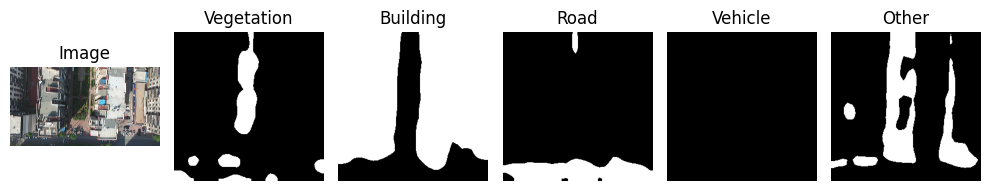

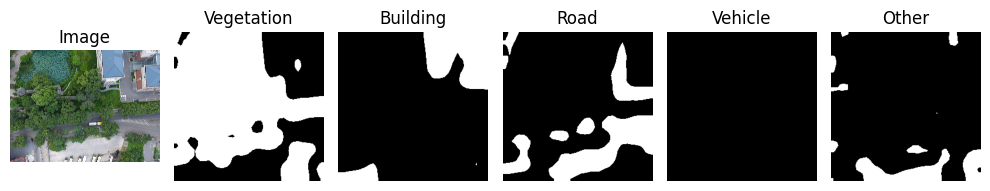

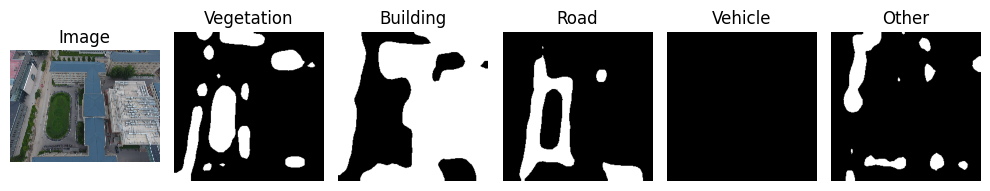

In [ ]:
model_path = "./data/UDD5/checkpoint.pth.tar"
labels = ["Vegetation","Building","Road","Vehicle","Other"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/UDD5/val/src/000261.JPG')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/UDD5/val/src/DJI_0451.JPG')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/UDD5/val/src/DJI_0532.JPG')
fig = model.predict_masks(image, labels, transform)